# Phase 3 — Qwen3-4B-Instruct-2507 Smoketest

## 1. Objective / Context
**WHY:** Memastikan kelayakan inferensi model *Qwen3-4B-Instruct-2507* pada lingkungan Google Colab (1 GPU). *Smoketest* ini mengeksekusi 10 baris data dari sampel Pilot untuk memverifikasi manajemen memori (OOM *mitigation* dengan *4-bit quantization*), *parsing* output, dan stabilitas *runtime* sebelum melakukan inferensi besar-besaran di *Main Experiment*.

## 2. Setup & Google Drive Mount
**WHY:** Membangun *persistence* model. Dengan mengarahkan `HF_HOME` ke Google Drive, kita memastikan bahwa bobot raksasa (3GB+) dari model HuggingFace hanya perlu diunduh satu kali saja dan tersimpan selamanya. Semua log hasil (JSONL) juga akan dicadangkan secara *real-time* ke Drive untuk mencegah kehilangan data jika Colab *disconnect*.

In [1]:
import os
import json
import time
import gc

# Konfigurasi MLOps Arsitektur
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')

# Mengarahkan Cache HuggingFace ke Google Drive agar Reusable!
os.environ['HF_HOME'] = MODELS_DIR

# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    # Authenticate to HuggingFace
    secrets_path = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[INFO] Successfully authenticated to HuggingFace Hub.")
except ImportError:
    print("[INFO] Not in Colab environment. Using local storage.")
    
# Initialize Directory Structure
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print(f"[INFO] Storage Architecture initialized at {PROJECT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Successfully authenticated to HuggingFace Hub.
[INFO] Storage Architecture initialized at /content/drive/MyDrive/LLMReliability


## 3. Dependencies & Data Loading
**WHY:** Mengimpor pustaka khusus inferensi (*PyTorch*, *Transformers*, *BitsAndBytes*) dan memuat porsi uji coba (10 baris pertama) dari dataset Pilot yang telah diverifikasi di Fase 2.

In [2]:
!pip install -q -U transformers accelerate bitsandbytes datasets pandas

import torch
import pandas as pd
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
try:
    df_pilot = pd.read_parquet(pilot_path)
    df_smoketest = df_pilot.head(10).copy()
    print(f"[INFO] Successfully loaded {len(df_smoketest)} samples for smoketest.")
except FileNotFoundError:
    print(f"[ERROR] Pilot dataset not found at {pilot_path}. Please run Notebook 01 first.")

[INFO] Successfully loaded 10 samples for smoketest.


## 4. Prompt Formatting & Position Swapping
**WHY:** Mendefinisikan template P1 (*Direct*) dari *Project Knowledge Base* dengan posisi kandidat AB, lalu memformatnya menggunakan *chat template* bawaan (native) dari Qwen3 agar model menerima konteks percakapan dengan standar pabriknya.

In [3]:
# Eksperimen Kondisi: P1 (Direct Prompt) + Posisi AB
def format_prompt_P1_AB(input_text: str, resp_A: str, resp_B: str) -> str:
    prompt = (
        "Bandingkan Response A dan Response B.\n"
        "Pilih respons yang lebih baik.\n"
        "Jawab hanya dengan A atau B.\n\n"
        f"[Input]\n{input_text}\n\n"
        f"[Response A]\n{resp_A}\n\n"
        f"[Response B]\n{resp_B}"
    )
    return prompt

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "You are a helpful and precise assistant."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

## 5. Smoke Test Inference Model Loading
**WHY:** Menginisialisasi *Qwen3-4B-Instruct-2507* menggunakan **Kuantisasi 4-bit (NF4)** dan tipe komputasi `bfloat16`. Ini adalah teknik paling krusial dalam *AI Engineering* 2026 untuk mengompres ukuran GPU VRAM yang dibutuhkan (dari 9GB+ menjadi sekitar 3-4GB).

In [4]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"

print(f"[INFO] Initializing tokenizer for {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print(f"[INFO] Initializing model {MODEL_ID} with 4-bit quantization...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)
print("[INFO] Model successfully loaded into GPU memory!")

[INFO] Initializing tokenizer for Qwen/Qwen3-4B-Instruct-2507...
[INFO] Initializing model Qwen/Qwen3-4B-Instruct-2507 with 4-bit quantization...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[INFO] Model successfully loaded into GPU memory!


## 6. Batched Evaluation (with Incremental Save)
**WHY:** Mengeksekusi inferensi satu per satu (*batch_size=1*) untuk mengontrol konsumsi VRAM secara mutlak. Kami menggunakan parameter deterministik (`temperature=0.0`) dan membatasi ukuran jawaban secara agresif (`max_new_tokens=8`). Hasilnya disimpan di setiap putaran untuk mencegah musibah diskoeksi Colab.

In [5]:
smoketest_results_path = os.path.join(RESULTS_DIR, 'smoketest_outputs.jsonl')
results = []

print(f"[INFO] Starting Smoketest Inference on {len(df_smoketest)} records...")

# Optimization: Inference Mode prevents PyTorch from storing computational graphs (Saves Memory)
with torch.inference_mode():
    for index, row in df_smoketest.iterrows():
        start_time = time.time()
        
        # 1. Prepare Content
        raw_prompt = format_prompt_P1_AB(row['input'], row['response_1'], row['response_2'])
        formatted_prompt = apply_chat_template(tokenizer, raw_prompt)
        
        # 2. Tokenize
        inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)
        
        # 3. Generate (Deterministic & Short)
        # do_sample=False defaults to greedy decoding (no temperature needed)
        outputs = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
        
        # 4. Decode & TPS Calc
        input_len = inputs['input_ids'].shape[1]
        generated_tokens = outputs[0][input_len:]
        raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)
        
        runtime = time.time() - start_time
        output_len = len(generated_tokens)
        tps = output_len / runtime if runtime > 0 else 0
        
        # 5. Compile Result
        record = {
            "sample_id": int(row['original_id']),
            "domain": row['domain'],
            "prompt_id": "P1",
            "position": "AB",
            "human_preference": "A" if row['chosen_model'] == row['response_1'] else "B",
            "raw_output": raw_output,
            "runtime_sec": round(runtime, 2),
            "output_tokens": output_len,
            "tps": round(tps, 2)
        }
        results.append(record)
        
        # Incremental Save
        with open(smoketest_results_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps(record) + '\n')
            
        print(f"Sample {row['original_id']} | Output: '{raw_output}' | TPS: {tps:.2f} | Time: {runtime:.2f}s")
        
        # 6. Garbage Collection (OOM Mitigation)
        del inputs, outputs
        torch.cuda.empty_cache()
        import gc
        gc.collect()

print(f"\n[INFO] Smoketest complete! Results incrementally saved to: {smoketest_results_path}")

[INFO] Starting Smoketest Inference on 10 records...
Sample 463 | Output: 'B' | TPS: 0.38 | Time: 5.31s
Sample 127 | Output: 'B' | TPS: 0.65 | Time: 3.06s
Sample 258 | Output: 'A' | TPS: 2.82 | Time: 0.71s
Sample 223 | Output: 'A' | TPS: 0.21 | Time: 9.61s
Sample 35 | Output: 'B' | TPS: 2.05 | Time: 0.97s
Sample 423 | Output: 'A' | TPS: 1.12 | Time: 1.78s
Sample 342 | Output: 'B' | TPS: 0.64 | Time: 3.15s
Sample 240 | Output: 'B' | TPS: 2.81 | Time: 0.71s
Sample 482 | Output: 'B' | TPS: 0.26 | Time: 7.71s
Sample 186 | Output: 'B' | TPS: 0.54 | Time: 3.71s

[INFO] Smoketest complete! Results incrementally saved to: /content/drive/MyDrive/LLMReliability/results/smoketest_outputs.jsonl


## 7. Metrics, Parsing & Error Analysis
**WHY:** Sebuah model *Judge* tidak berguna jika *output*-nya tidak bisa dibaca oleh mesin. Tahapan ini membersihkan *string* jawaban model (*strip*, huruf besar) dan mendeteksi apakah model hanya menjawab 'A' atau 'B', atau malah gagal mengikuti format (*invalid*).

=== SMOKETEST SEMANTIC AUDIT ===


,sample_id,domain,human_preference,raw_output,parsed_decision
0,463,analysis,B,B,B
1,127,coding,B,B,B
2,258,translation,B,A,A
3,223,summarization,B,A,A
4,35,math,B,B,B
5,423,brainstorming,B,A,A
6,342,open question,B,B,B
7,240,translation,B,B,B
8,482,analysis,B,B,B
9,186,summarization,B,B,B


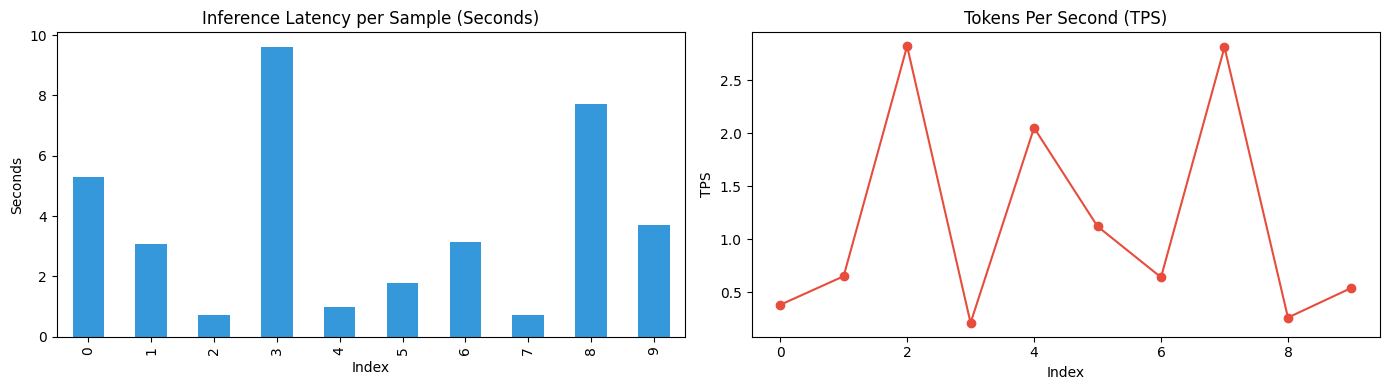


=== SMOKETEST SUMMARY ===
Total Samples: 10
Valid Parsing: 10
Invalid Parsing: 0 (0.0%)
Average Runtime: 3.67 seconds/sample
Average TPS: 1.15 tokens/sec
[INFO] Smoketest sukses memenuhi standar reliabilitas parsing!


In [6]:
import re
import pandas as pd
import matplotlib.pyplot as plt

def parse_decision(raw_output: str) -> str:
    clean_text = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

valid_count = 0
invalid_count = 0

for r in results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed
    if parsed in ["A", "B"]:
        valid_count += 1
    else:
        invalid_count += 1

# Create DataFrame for Observability
df_results = pd.DataFrame(results)

print("=== SMOKETEST SEMANTIC AUDIT ===")
display(df_results[['sample_id', 'domain', 'human_preference', 'raw_output', 'parsed_decision']])

# Performance Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_results['runtime_sec'].plot(kind='bar', color='#3498db', ax=axes[0])
axes[0].set_title('Inference Latency per Sample (Seconds)')
axes[0].set_xlabel('Index')
axes[0].set_ylabel('Seconds')

df_results['tps'].plot(kind='line', marker='o', color='#e74c3c', ax=axes[1])
axes[1].set_title('Tokens Per Second (TPS)')
axes[1].set_xlabel('Index')
axes[1].set_ylabel('TPS')

plt.tight_layout()
plt.show()

invalid_rate = (invalid_count / len(results)) * 100
avg_runtime = df_results["runtime_sec"].mean()
avg_tps = df_results["tps"].mean()

print("\n=== SMOKETEST SUMMARY ===")
print(f"Total Samples: {len(results)}")
print(f"Valid Parsing: {valid_count}")
print(f"Invalid Parsing: {invalid_count} ({invalid_rate:.1f}%)")
print(f"Average Runtime: {avg_runtime:.2f} seconds/sample")
print(f"Average TPS: {avg_tps:.2f} tokens/sec")

assert invalid_rate < 20.0, "FATAL: Parser gagal mengurai terlalu banyak respons. Perbaiki Prompt atau Parser!"
print("[INFO] Smoketest sukses memenuhi standar reliabilitas parsing!")